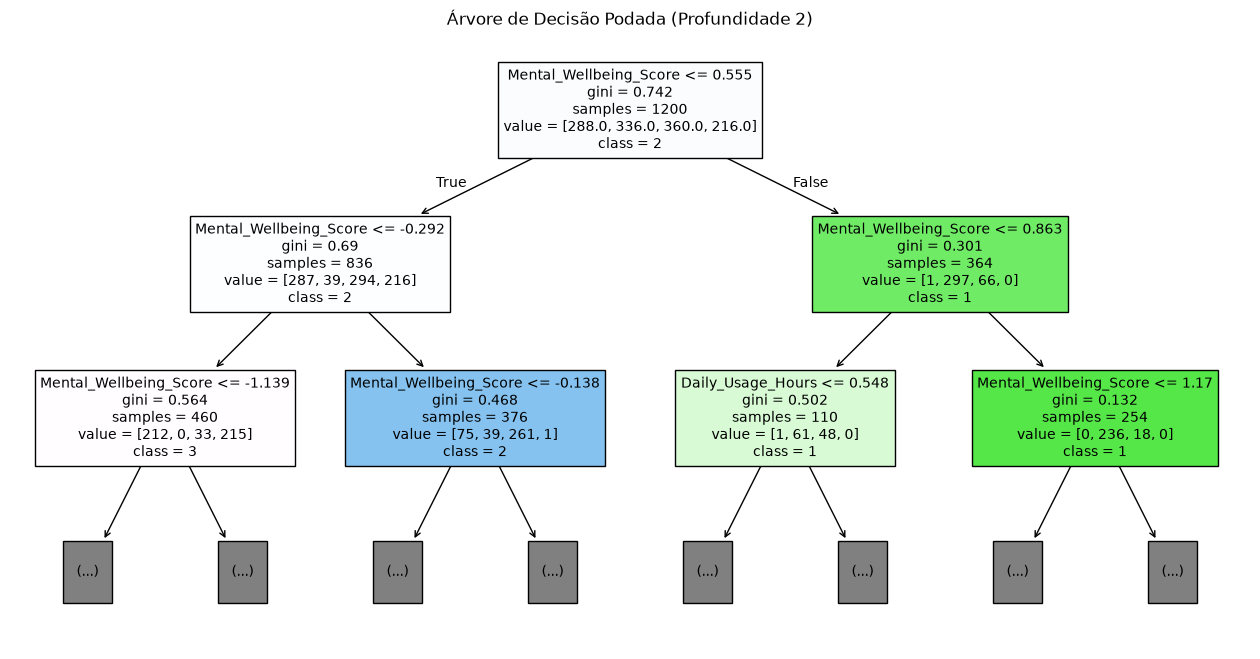

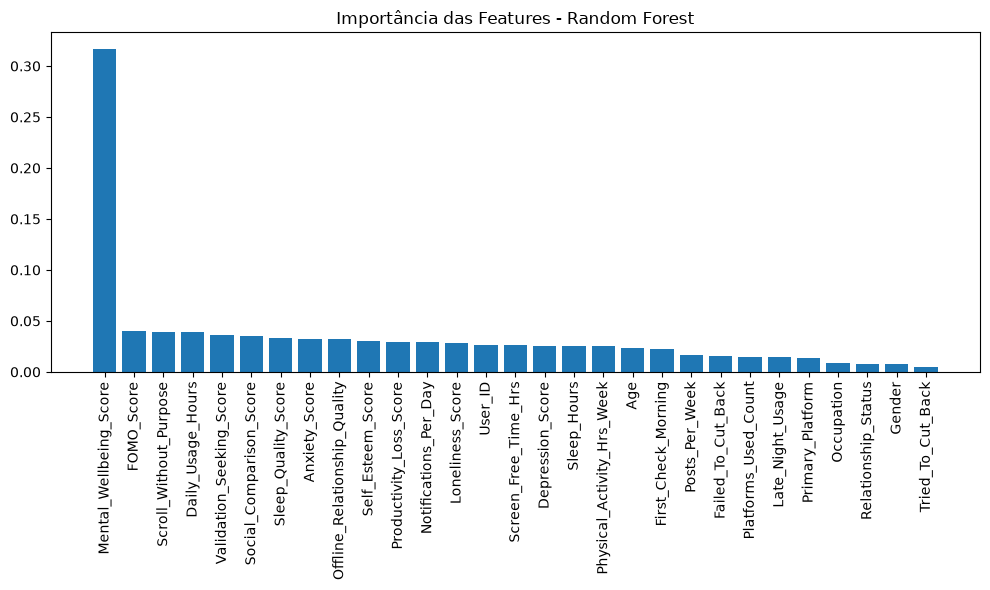

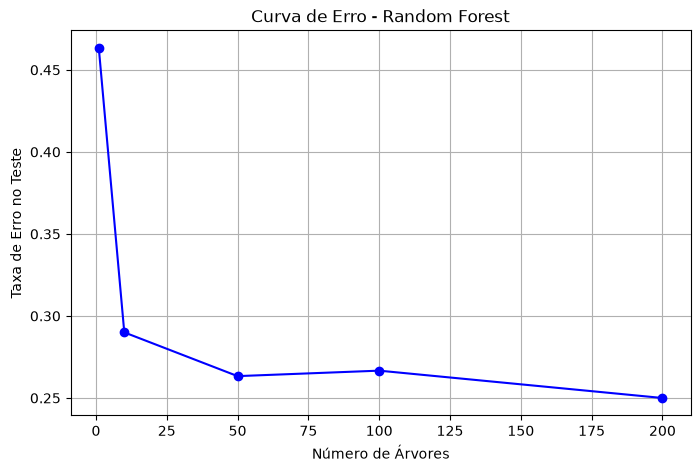

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# 0. Criar pasta se não existir e carregar dados
os.makedirs('../reports/figures', exist_ok=True)
train_df = pd.read_csv('../data/processed/train_classification.csv')
test_df = pd.read_csv('../data/processed/test_classification.csv')
X_train, y_train = train_df.drop(columns=['Addiction_Level']), train_df['Addiction_Level']
X_test, y_test = test_df.drop(columns=['Addiction_Level']), test_df['Addiction_Level']

# 1. Retreinar Modelos
best_tree = DecisionTreeClassifier(criterion='gini', max_depth=3, min_samples_leaf=10, min_samples_split=2, random_state=42)
best_tree.fit(X_train, y_train)

rf_clf = RandomForestClassifier(random_state=42, n_jobs=-1)
rf_clf.fit(X_train, y_train)

# 2. Visualização da Árvore de Decisão
plt.figure(figsize=(16, 8))
plot_tree(best_tree, feature_names=X_train.columns, class_names=['0', '1', '2', '3'], filled=True, max_depth=2, fontsize=10)
plt.title("Árvore de Decisão Podada (Profundidade 2)")
plt.savefig('../reports/figures/decision_tree_plot.png', bbox_inches='tight')
plt.show()

# 3. Importância das Features
importances = rf_clf.feature_importances_
indices = np.argsort(importances)[::-1]
plt.figure(figsize=(10, 6))
plt.title("Importância das Features - Random Forest")
plt.bar(range(X_train.shape[1]), importances[indices], align="center")
plt.xticks(range(X_train.shape[1]), X_train.columns[indices], rotation=90)
plt.tight_layout()
plt.savefig('../reports/figures/rf_feature_importance.png')
plt.show()

# 4. Curva de Erro vs Número de Árvores
n_estimators = [1, 10, 50, 100, 200]
erros = [1 - accuracy_score(y_test, RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1).fit(X_train, y_train).predict(X_test)) for n in n_estimators]

plt.figure(figsize=(8, 5))
plt.plot(n_estimators, erros, marker='o', linestyle='-', color='b')
plt.xlabel('Número de Árvores')
plt.ylabel('Taxa de Erro no Teste')
plt.title('Curva de Erro - Random Forest')
plt.grid(True)
plt.savefig('../reports/figures/rf_error_curve.png')
plt.show()

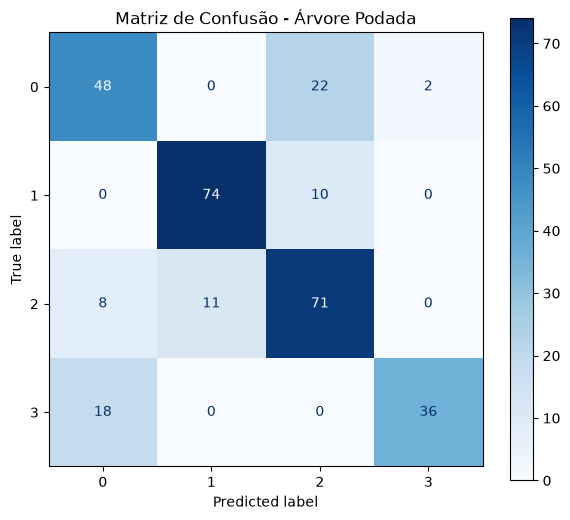

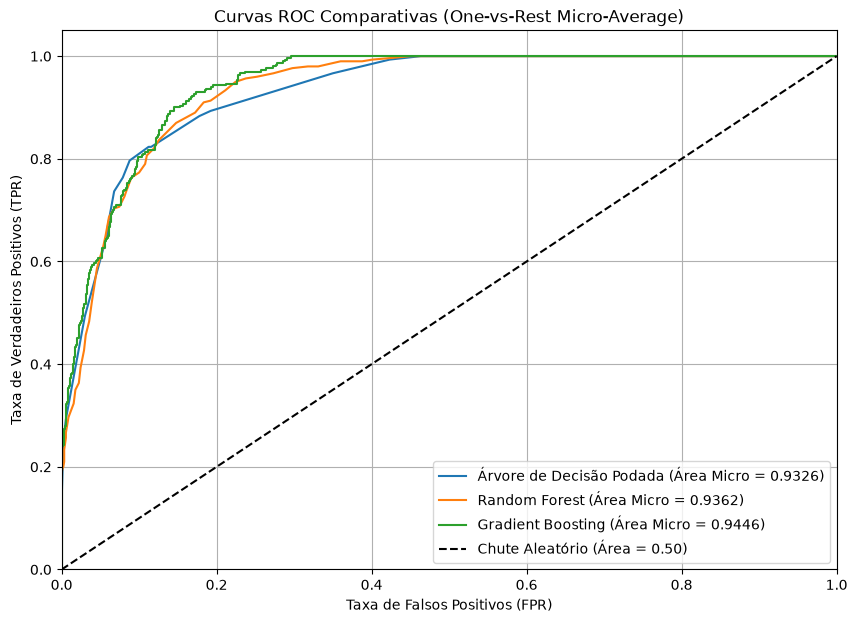

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.ensemble import GradientBoostingClassifier

# 1. Matriz de Confusão para a Árvore de Decisão Podada
y_pred_tree = best_tree.predict(X_test)
cm = confusion_matrix(y_test, y_pred_tree)

fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['0', '1', '2', '3'])
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title("Matriz de Confusão - Árvore Podada")
plt.savefig('../reports/figures/confusion_matrix_tree.png', bbox_inches='tight')
plt.show()

# 2. Curvas ROC Multiclasse (One-vs-Rest)
# Binarizar os rótulos de teste para ROC-AUC multiclasse
y_test_bin = label_binarize(y_test, classes=[0, 1, 2, 3])
n_classes = y_test_bin.shape[1]

# Instanciar e treinar Gradient Boosting para comparação no gráfico
gb_clf = GradientBoostingClassifier(random_state=42)
gb_clf.fit(X_train, y_train)

models = {
    'Árvore de Decisão Podada': best_tree,
    'Random Forest': rf_clf,
    'Gradient Boosting': gb_clf
}

plt.figure(figsize=(10, 7))

for name, model in models.items():
    y_score = model.predict_proba(X_test)
    # Calcular curva ROC micro-average (média global de todas as classes)
    fpr, tpr, _ = roc_curve(y_test_bin.ravel(), y_score.ravel())
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} (Área Micro = {roc_auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', label='Chute Aleatório (Área = 0.50)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
plt.title('Curvas ROC Comparativas (One-vs-Rest Micro-Average)')
plt.legend(loc="lower right")
plt.grid(True)
plt.savefig('../reports/figures/roc_curves_comparison.png', bbox_inches='tight')
plt.show()